# Week 03 - Graded Lab: Frozen Lake

**Team:** _Name 1_, _Name 2_

Structure of this notebook:

1. Setup: parameters, environment, generic training loop `run_env`
2. **Task 1**: Monte Carlo with a random policy
3. **Task 2**: Incremental Monte Carlo with ε-greedy
4. **Task 3**: Q-learning with ε-greedy
5. Comparison (4x4 vs 11x11) and report

The base classes `Learner`, `EpisodicLearner` and `Explorer` live in `misc.py`.
Every place where you have to write code is marked with `TODO` and a
`raise NotImplementedError(...)`. Delete the `raise` line once you've written the code.

In [67]:
# %pip install -r requirements.txt

In [68]:
import re
from pathlib import Path
from typing import NamedTuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
from tqdm import tqdm

from misc import (
    EpisodicLearner,
    Explorer,
    Learner,
    Transition,
    plot_q_values_map,
    plot_states_actions_distribution,
    postprocess,
)

sns.set_theme()

## Setup

In [69]:
class Params(NamedTuple):
    total_episodes: int  # Total episodes
    learning_rate: float  # Learning rate (alpha)
    gamma: float  # Discounting rate
    epsilon: float  # Exploration probability
    map_size: int  # Number of tiles of one side of the squared environment
    max_episode_steps: int  # Episode is truncated after this many steps
    seed: int  # Define a seed so that we get reproducible results
    is_slippery: bool  # If true the player moves in the intended direction with probability 1/3, else in either perpendicular direction
    n_runs: int  # Number of runs
    action_size: int  # Number of possible actions (filled in by make_env)
    state_size: int  # Number of possible states (filled in by make_env)
    proba_frozen: float  # Probability that a tile is frozen
    savefig_folder: Path  # Root folder where plots are saved


params = Params(
    total_episodes=2000,
    learning_rate=0.8,
    gamma=0.95,
    epsilon=0.1,
    map_size=4,  # start small, switch to 11 for the comparison
    max_episode_steps=100,  # FrozenLake default; consider more for 11x11
    seed=123,
    is_slippery=True,
    n_runs=20,
    action_size=None,
    state_size=None,
    proba_frozen=0.9,
    savefig_folder=Path("./_static/img"),
)

# Random generator used by our own code (e.g. the epsilon-greedy coin flip)
rng = np.random.default_rng(params.seed)

# Create the figure folder if it doesn't exist
params.savefig_folder.mkdir(parents=True, exist_ok=True)

In [70]:
def make_env(params):
    """Create the Frozen Lake env and return it together with params that know the state/action sizes."""
    env = gym.make(
        "FrozenLake-v1",
        is_slippery=params.is_slippery,
        render_mode="rgb_array",
        max_episode_steps=params.max_episode_steps,
        desc=generate_random_map(
            size=params.map_size, p=params.proba_frozen, seed=params.seed
        ),
    )
    env.action_space.seed(params.seed)  # reproducible action_space.sample()
    params = params._replace(
        action_size=env.action_space.n,
        state_size=env.observation_space.n,
    )
    return env, params


env, params = make_env(params)
print(f"Action size: {params.action_size}")
print(f"State size: {params.state_size}")
env.close()

Action size: 4
State size: 16


### Generic training loop

`run_env` works for **every** learner/explorer combination. It only uses the interface from `misc.py`:

| Call | When | Who does real work here |
|---|---|---|
| `learner.reset()` | start of every run | everyone |
| `explorer.choose_action(action_space, state, qtable)` | every step | the policy |
| `learner.observe(state, action, reward, new_state, terminated)` | after every step | **Q-learning** (MC only records the step) |
| `learner.end_episode()` | end of every episode | **Monte Carlo** (Q-learning does nothing) |

In [71]:
def run_env(learner: Learner, explorer: Explorer, env, params):
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    qtables = np.zeros((params.n_runs, params.state_size, params.action_size))
    all_states = []
    all_actions = []

    for run in range(params.n_runs):  # Run several times to account for stochasticity
        learner.reset()  # Every run starts from scratch

        for episode in tqdm(
            episodes, desc=f"Run {run}/{params.n_runs} - Episodes", leave=False
        ):
            # Seed only the first reset of a run. Re-seeding every episode would
            # replay the exact same "slips" over and over again.
            seed = params.seed + run if episode == 0 else None
            state = env.reset(seed=seed)[0]
            step = 0
            done = False
            total_rewards = 0

            while not done:
                action = explorer.choose_action(env.action_space, state, learner.qtable)

                # Log all states and actions
                all_states.append(state)
                all_actions.append(action)

                new_state, reward, terminated, truncated, info = env.step(action)

                done = terminated or truncated

                learner.observe(state, action, reward, new_state, terminated) # Observe feeds Monte Carlo and Q-learning

                total_rewards += reward
                step += 1
                state = new_state

            learner.end_episode() # Monte Carlo needs to know when the episode ends

            # Log all rewards and steps
            rewards[episode, run] = total_rewards
            steps[episode, run] = step
        qtables[run] = learner.qtable

    return rewards, steps, episodes, qtables, all_states, all_actions

In [72]:
def run_experiment(label, make_learner, make_explorer, params, plots=True):
    """Build env + agent, train, and return result dataframes and the run-averaged Q-table.

    make_learner / make_explorer are functions params -> Learner / Explorer, because the
    state size is only known after the environment was created.
    """
    env, params = make_env(params)
    learner = make_learner(params)
    explorer = make_explorer(params)

    rewards, steps, episodes, qtables, all_states, all_actions = run_env(
        learner, explorer, env, params
    )

    res, st = postprocess(episodes, params, rewards, steps, params.map_size)
    res["method"] = label
    st["method"] = label
    qtable = qtables.mean(axis=0)  # Average the Q-table over runs

    if plots:
        img_label = re.sub(r"\W+", "_", label.lower()).strip("_")
        # Heatmap = V(s) = max_a Q(s, a), arrows = greedy policy
        plot_q_values_map(qtable, env, params.map_size, params=params, img_label=img_label)
        plot_states_actions_distribution(
            states=all_states, actions=all_actions, map_size=params.map_size,
            params=params, img_label=img_label,
        )

    env.close()
    return res, st, qtable

## Task 1: Monte Carlo with a random policy

Idea: play a **whole** episode, then for every step compute the return

$$G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$$

and estimate $Q(s,a)$ as the **average of all returns** observed after taking $a$ in $s$ (Week 1 style: keep a list, take the mean).

Choose **First-Visit** (only the first occurrence of $(s,a)$ per episode counts) or **Every-Visit** (all occurrences count) and write your choice in the report.

In [73]:
def compute_returns(trajectory, gamma):
    """Return a list `returns` with returns[t] = G_t for every step t of the trajectory."""
    G = 0
    returns = []
    for step in reversed(trajectory):
        G = step.reward + gamma * G
        returns.append(G)
    return returs[::-1] # reverse so returns[t] matches trajectory[t]


class RandomPolicy(Explorer):
    """Ignores the Q-table and picks a uniformly random action."""

    def choose_action(self, action_space, state=None, qtable=None):
        return action_space.sample()  # ignore state and qtable, just return a random action


class MonteCarlo(EpisodicLearner):
    """Monte Carlo prediction: Q(s, a) = mean of all returns seen for (s, a)."""

    def __init__(self, gamma, state_size, action_size):
        self.gamma = gamma
        super().__init__(state_size, action_size)  # this also calls reset()

    def reset(self):
        super().reset()  # resets the Q-table and the trajectory buffer
        # One list of observed returns per (state, action) pair
        self.returns = [[[] for _ in range(self.action_size)] for _ in range(self.state_size)]

    def learn_from_episode(self, trajectory):
        # `trajectory` is a tuple of Transition(state, action, reward), oldest step first.
        returns = compute_returns(trajectory, self.gamma)
        visited_pairs = set()  # To track (state, action) pairs seen in this episode
        for (step, G) in zip(trajectory, returns):
            state, action = step.state, step.action
            if (state, action) in visited_pairs:
                continue  # Skip if already seen in this episode
            visited_pairs.add((state, action))
            self.returns[state][action].append(G)
            self.qtable[state, action] = np.mean(self.returns[state][action])

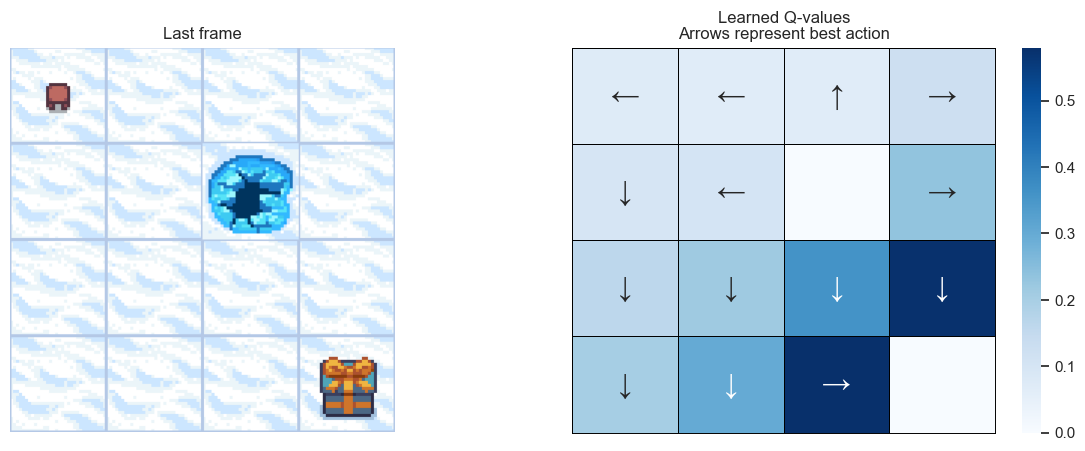

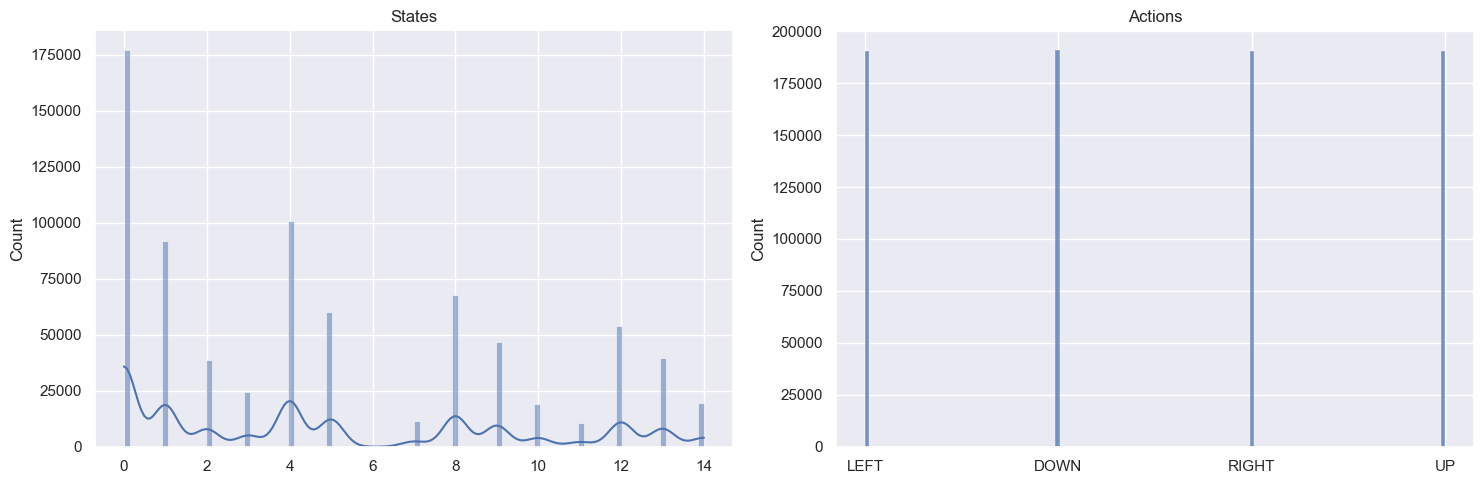

In [74]:
res_mc, st_mc, qtable_mc = run_experiment(
    label="MC random",
    make_learner=lambda p: MonteCarlo(gamma=p.gamma, state_size=p.state_size, action_size=p.action_size),
    make_explorer=lambda p: RandomPolicy(),
    params=params,
)

## Task 2: Incremental Monte Carlo with ε-greedy

Two changes compared to Task 1:

1. **Incremental update** (slide 30, top): no lists of returns any more, just a running mean

   $$N(s,a) \leftarrow N(s,a) + 1, \qquad Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)}\big(G_t - Q(s,a)\big)$$

   (optionally a constant step size $\alpha$ instead of $1/N$, which forgets old returns, useful because the policy keeps changing).

2. **The agent acts on what it learned:** ε-greedy instead of random.
   With probability ε explore (random action), otherwise exploit (best action in the Q-table).

In [75]:
class EpsilonGreedy(Explorer):
    def __init__(self, epsilon, rng):
        self.epsilon = epsilon
        self.rng = rng

    def choose_action(self, action_space, state, qtable):
        if self.rng.random() < self.epsilon:
            return action_space.sample() # Explore
        q = qtable[state]
        return self.rng.choice(np.flatnonzero(q == q.max())) # Exploit


class IncrementalMonteCarlo(EpisodicLearner):
    """Monte Carlo control with incremental updates.

    learning_rate=None -> step size 1/N(s, a) (exact running mean)
    learning_rate=a    -> constant step size a
    """

    def __init__(self, gamma, state_size, action_size, learning_rate=None):
        self.gamma = gamma
        self.learning_rate = learning_rate
        self.counts = np.zeros((state_size, action_size))
        super().__init__(state_size, action_size)

    def reset(self):
        super().reset()
        self.counts = np.zeros((self.state_size, self.action_size))

    def learn_from_episode(self, trajectory):
        returns = compute_returns(trajectory, self.gamma)
        visited_pairs = set()  # To track (state, action) pairs seen in this episode
        for (step, G) in zip(trajectory, returns):
            state, action = step.state, step.action
            if (state, action) in visited_pairs:
                continue  # Skip if already seen in this episode
            visited_pairs.add((state, action))
            self.counts[state, action] += 1
            step_size = self.learning_rate if self.learning_rate is not None else 1 / self.counts[state, action]
            self.qtable[state, action] += step_size * (G - self.qtable[state, action])

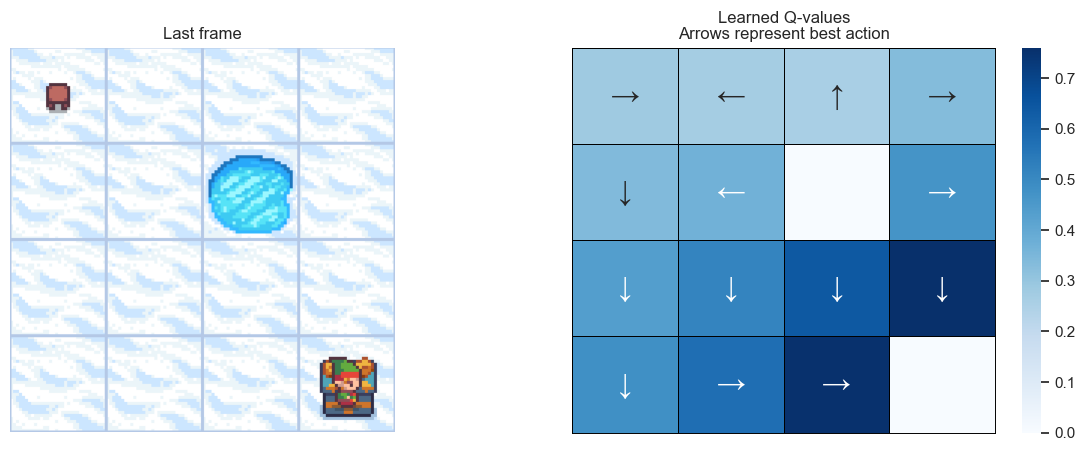

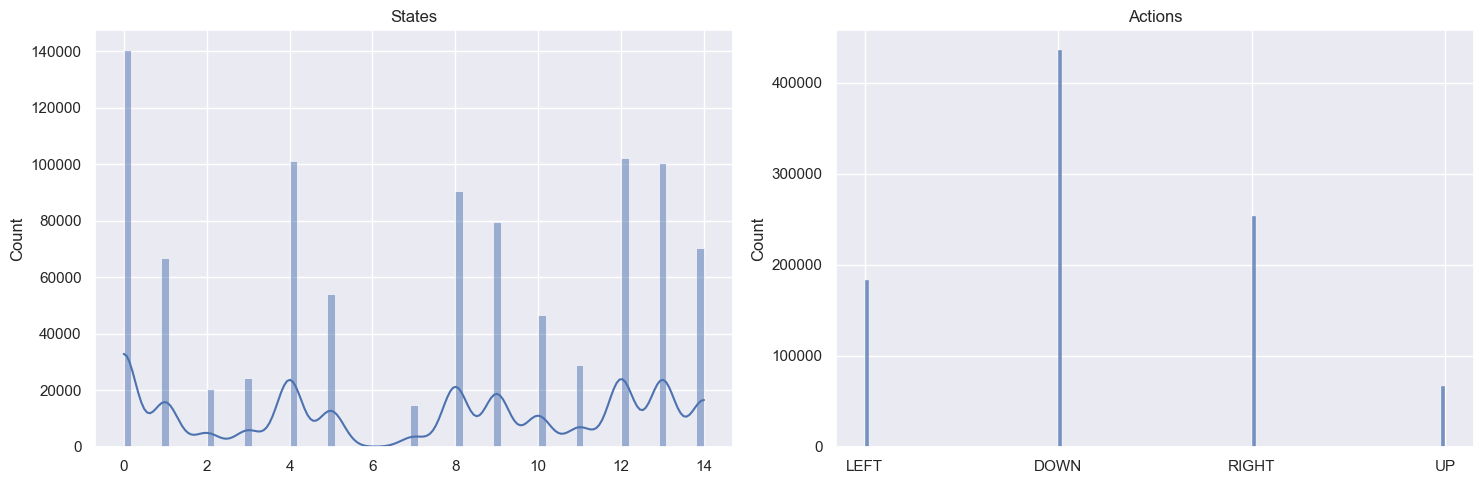

In [76]:
res_imc, st_imc, qtable_imc = run_experiment(
    label="Incremental MC",
    make_learner=lambda p: IncrementalMonteCarlo(
        gamma=p.gamma, state_size=p.state_size, action_size=p.action_size,
        learning_rate=None,  # try None (1/N) and a constant, e.g. 0.05
    ),
    make_explorer=lambda p: EpsilonGreedy(epsilon=p.epsilon, rng=rng),
    params=params,
)

## Task 3: Q-learning with ε-greedy

Q-learning updates **after every step** (temporal difference) and bootstraps from its own estimate of the next state:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big(\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{TD target}} - Q(s,a)\Big)$$

If $s'$ is terminal (hole or goal) there is no future: the TD target is just $r$.

In [77]:
class Qlearning(Learner):
    def __init__(self, learning_rate, gamma, state_size, action_size):
        self.learning_rate = learning_rate
        self.gamma = gamma
        super().__init__(state_size, action_size)

    def observe(self, state, action, reward, new_state, terminated):
        if terminated:
            target = reward
        else:
            target = reward + self.gamma * np.max(self.qtable[new_state, :])
        self.qtable[state, action] += self.learning_rate * (target - self.qtable[state, action])

    # end_episode(): nothing to do, the default from Learner is fine

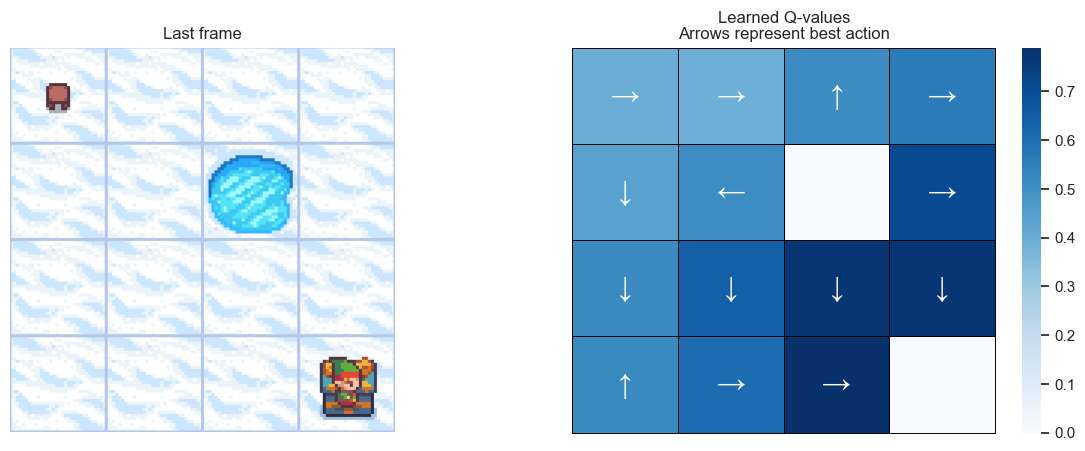

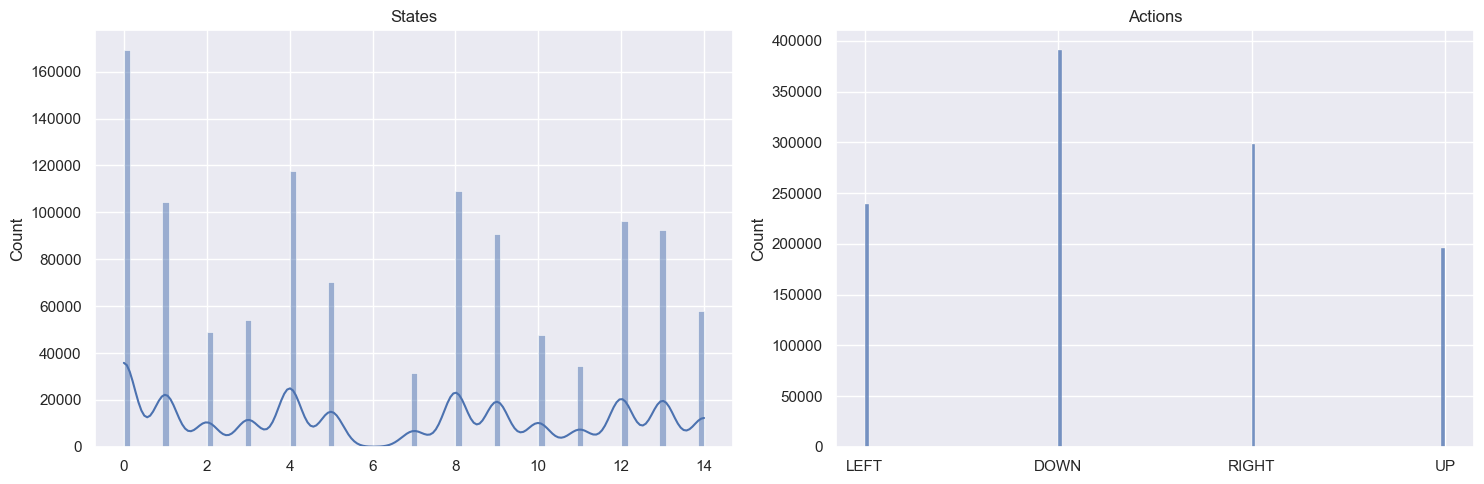

In [78]:
res_q, st_q, qtable_q = run_experiment(
    label="Q-learning",
    make_learner=lambda p: Qlearning(
        learning_rate=p.learning_rate, gamma=p.gamma,
        state_size=p.state_size, action_size=p.action_size,
    ),
    make_explorer=lambda p: EpsilonGreedy(epsilon=p.epsilon, rng=rng),
    params=params,
)

## Comparison: all methods, 4x4 vs 11x11

Hyperparameters per method are set here via `params._replace(...)`. Note in the report how you chose them
(e.g. a small grid search, averaged over `n_runs`).

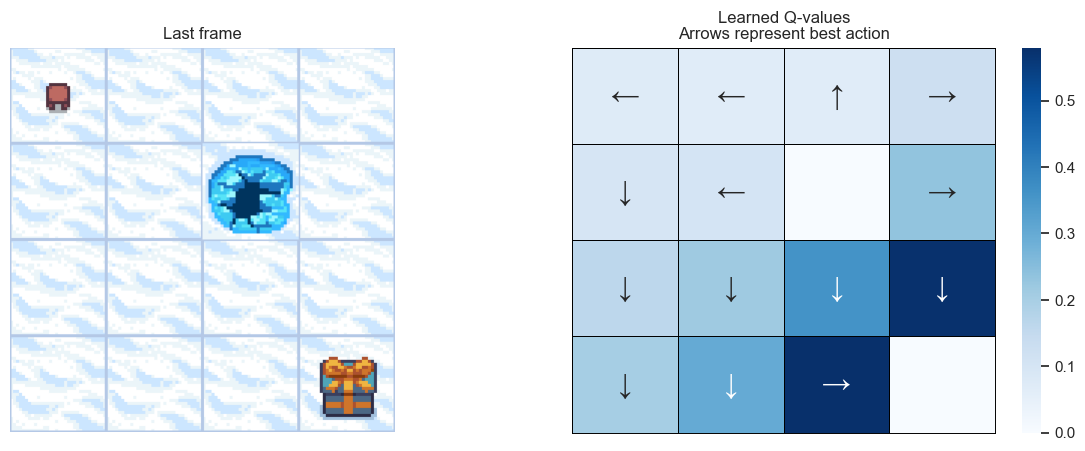

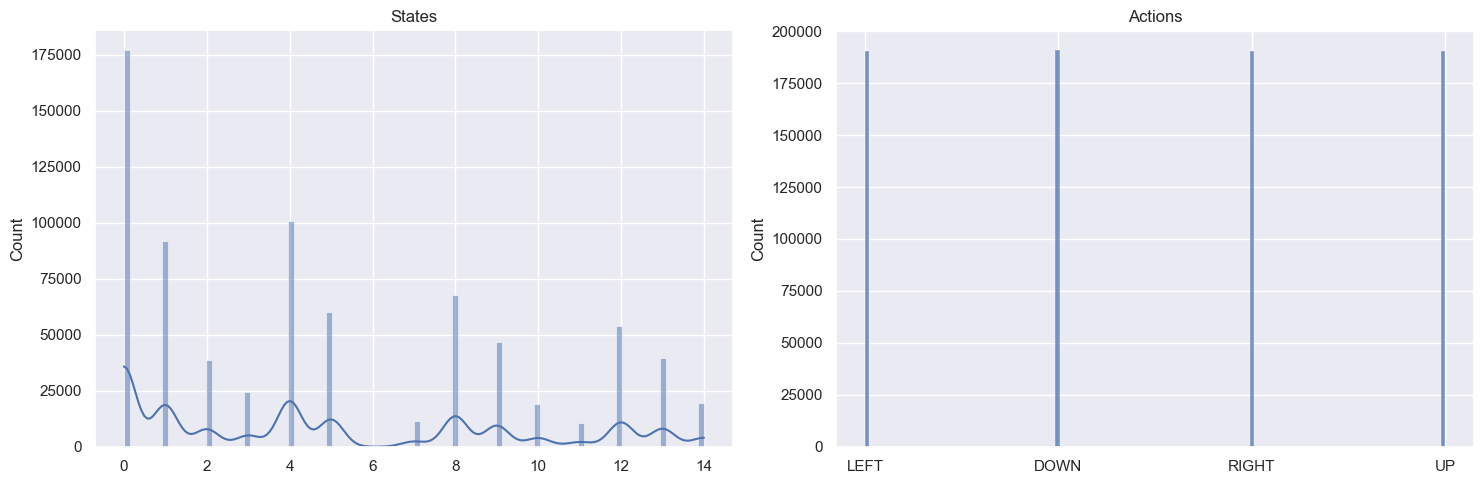

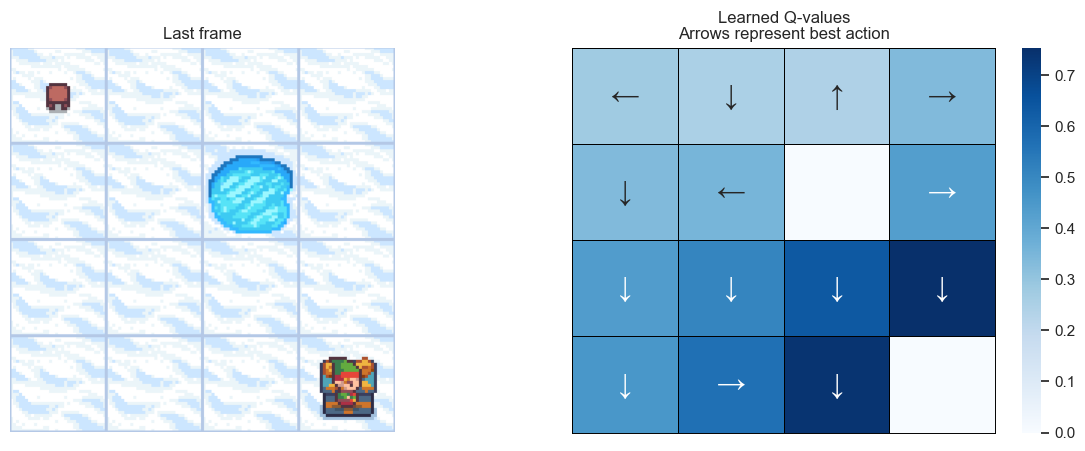

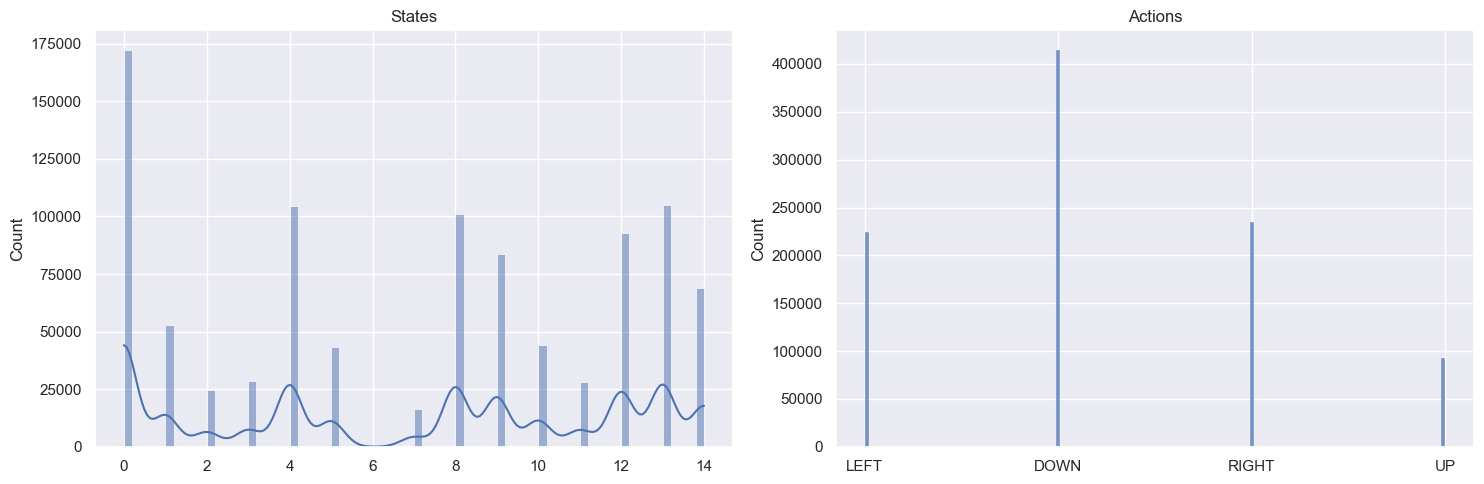

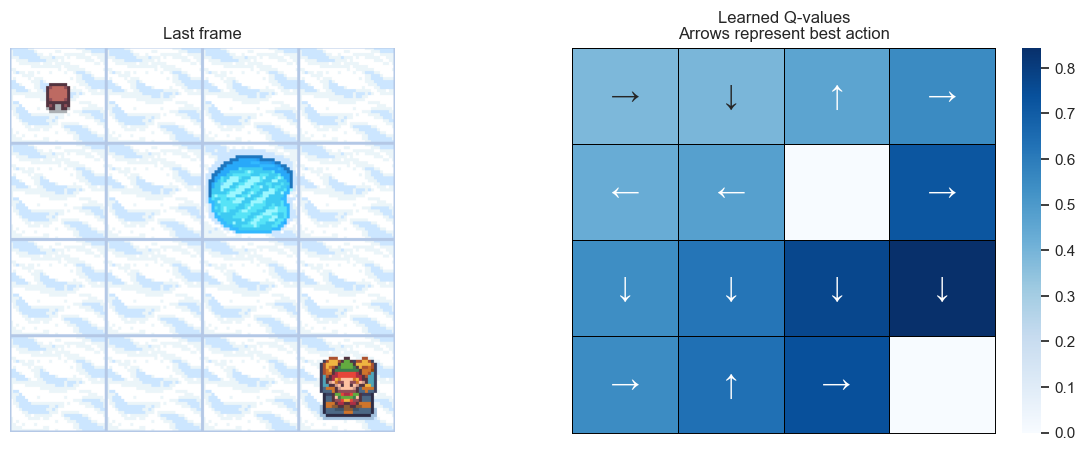

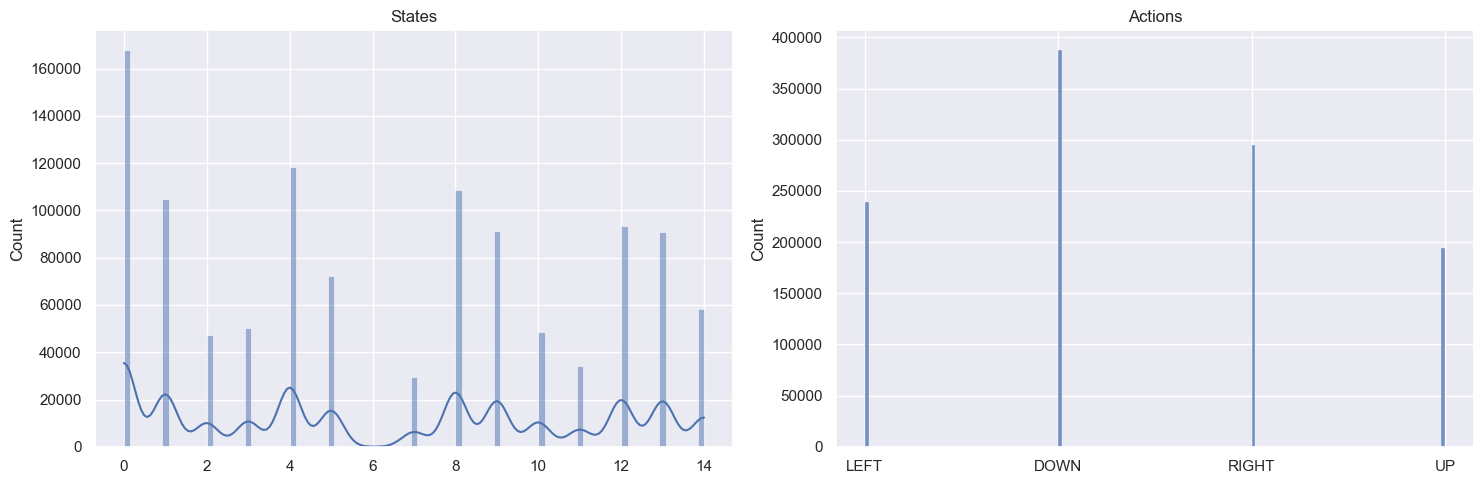

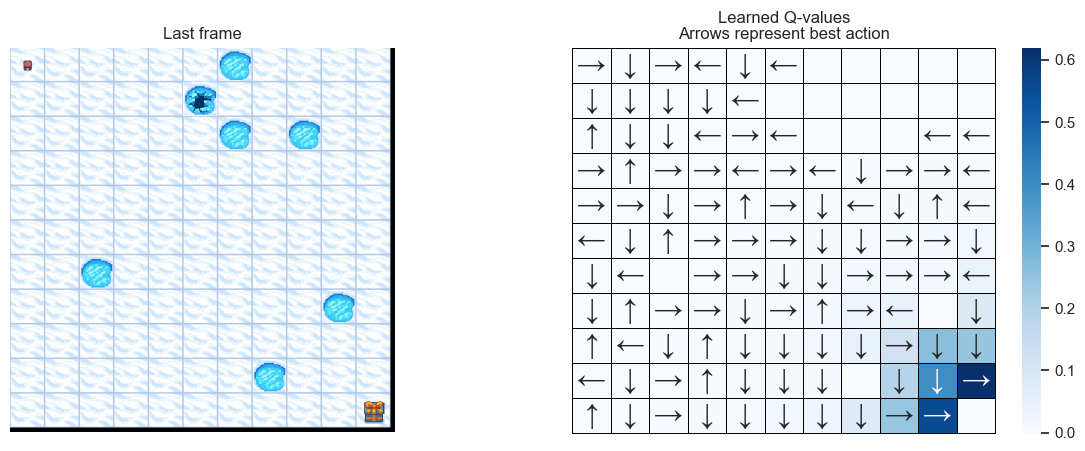

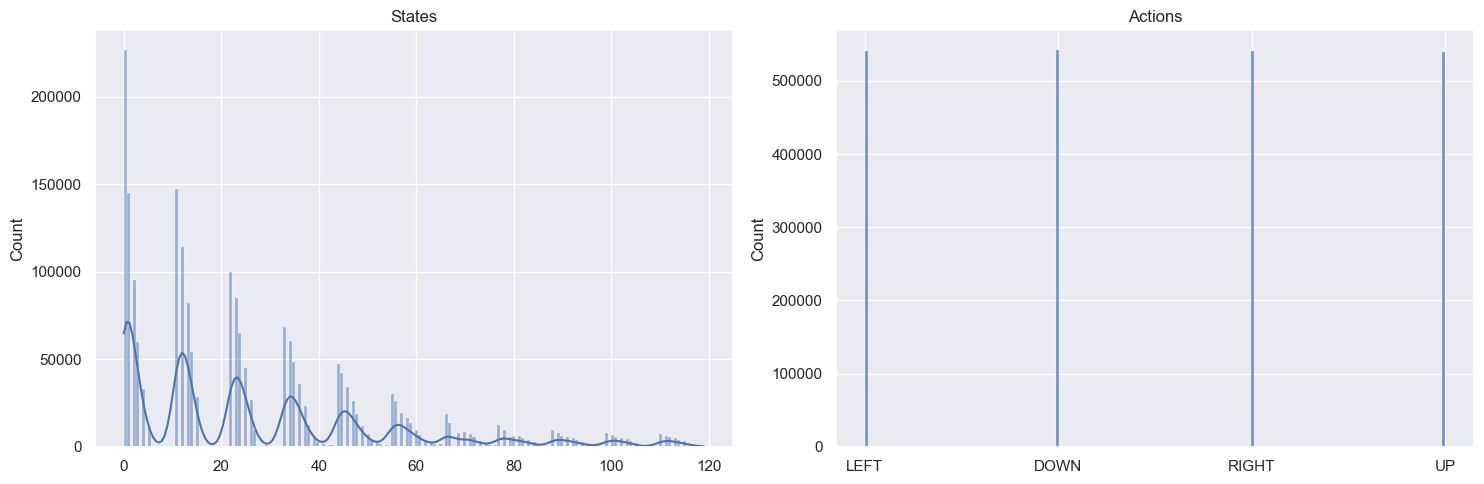

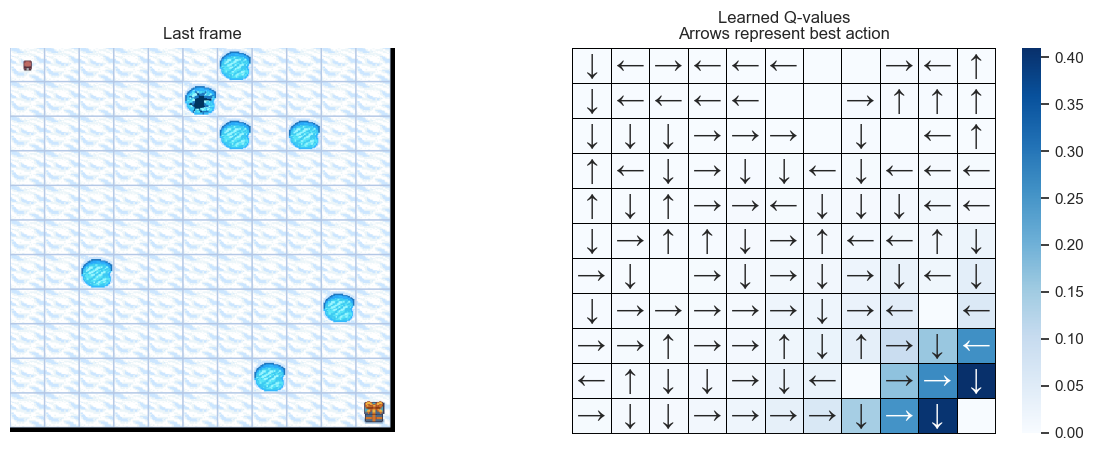

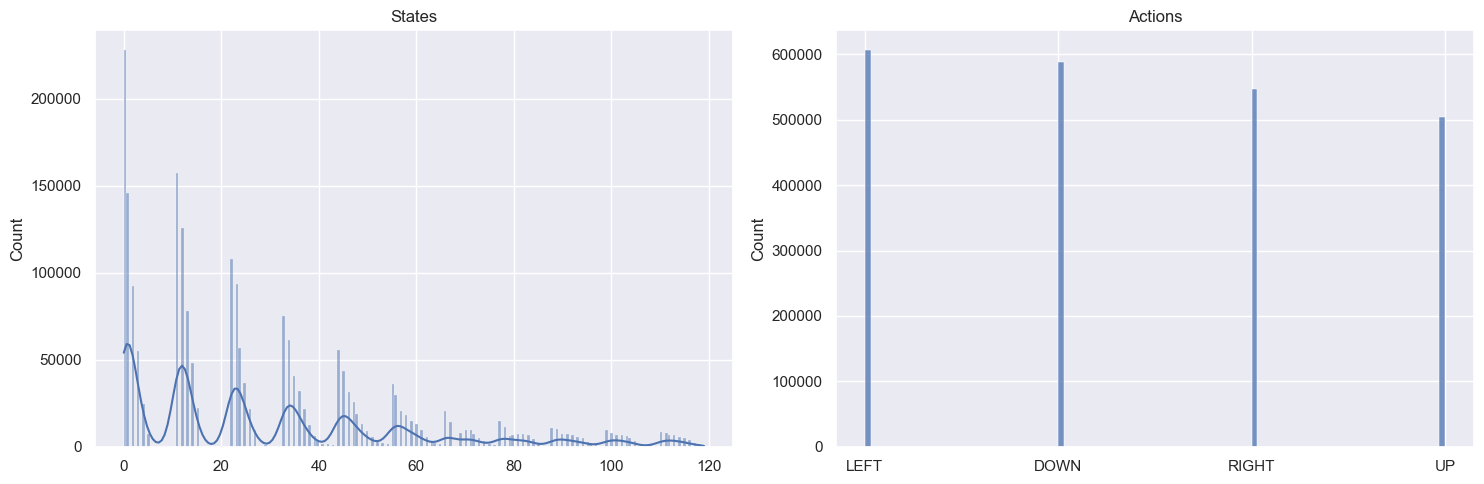

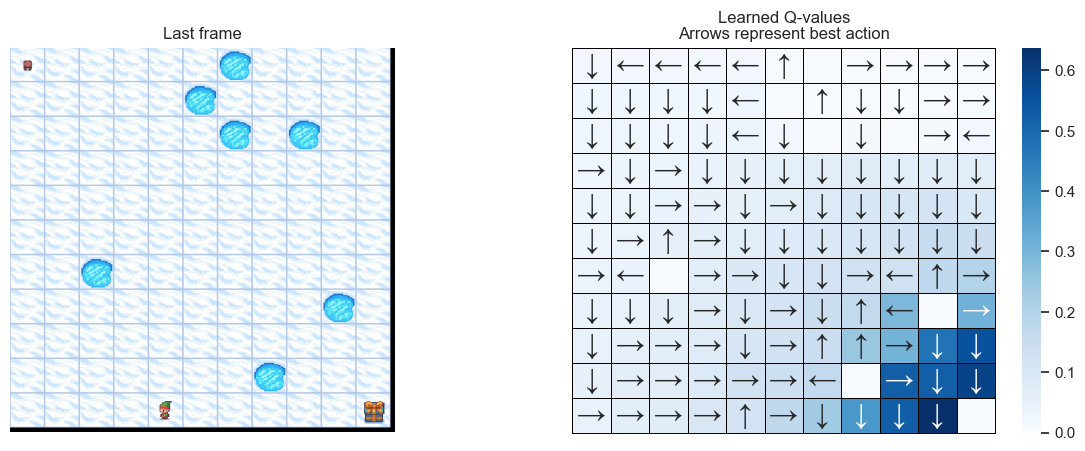

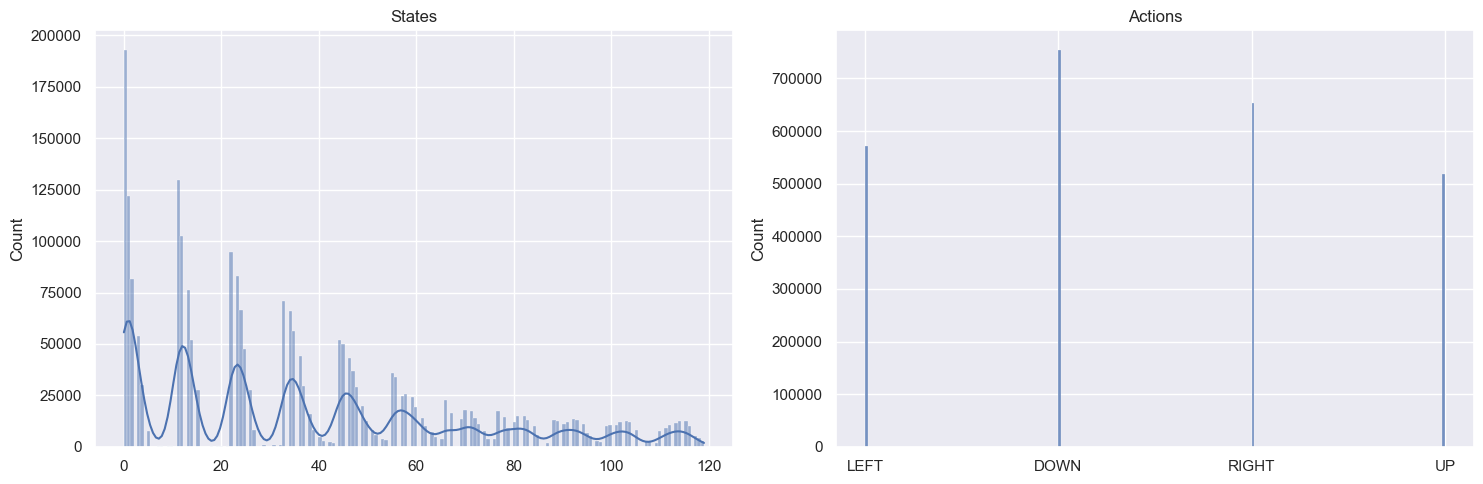

In [79]:
METHODS = {
    "MC random": (
        dict(),  # parameter overrides for this method
        lambda p: MonteCarlo(gamma=p.gamma, state_size=p.state_size, action_size=p.action_size),
        lambda p: RandomPolicy(),
    ),
    "Incremental MC": (
        dict(epsilon=0.1),
        lambda p: IncrementalMonteCarlo(gamma=p.gamma, state_size=p.state_size, action_size=p.action_size),
        lambda p: EpsilonGreedy(epsilon=p.epsilon, rng=rng),
    ),
    "Q-learning": (
        dict(epsilon=0.1, learning_rate=0.8),
        lambda p: Qlearning(learning_rate=p.learning_rate, gamma=p.gamma,
                            state_size=p.state_size, action_size=p.action_size),
        lambda p: EpsilonGreedy(epsilon=p.epsilon, rng=rng),
    ),
}

MAP_SIZES = [4, 11]

all_res, all_st, all_qtables = [], [], {}
for map_size in MAP_SIZES:
    for label, (overrides, make_learner, make_explorer) in METHODS.items():
        run_params = params._replace(map_size=map_size, **overrides)
        res, st, qtable = run_experiment(label, make_learner, make_explorer, run_params)
        all_res.append(res)
        all_st.append(st)
        all_qtables[(label, map_size)] = qtable

res_all = pd.concat(all_res, ignore_index=True)
st_all = pd.concat(all_st, ignore_index=True)

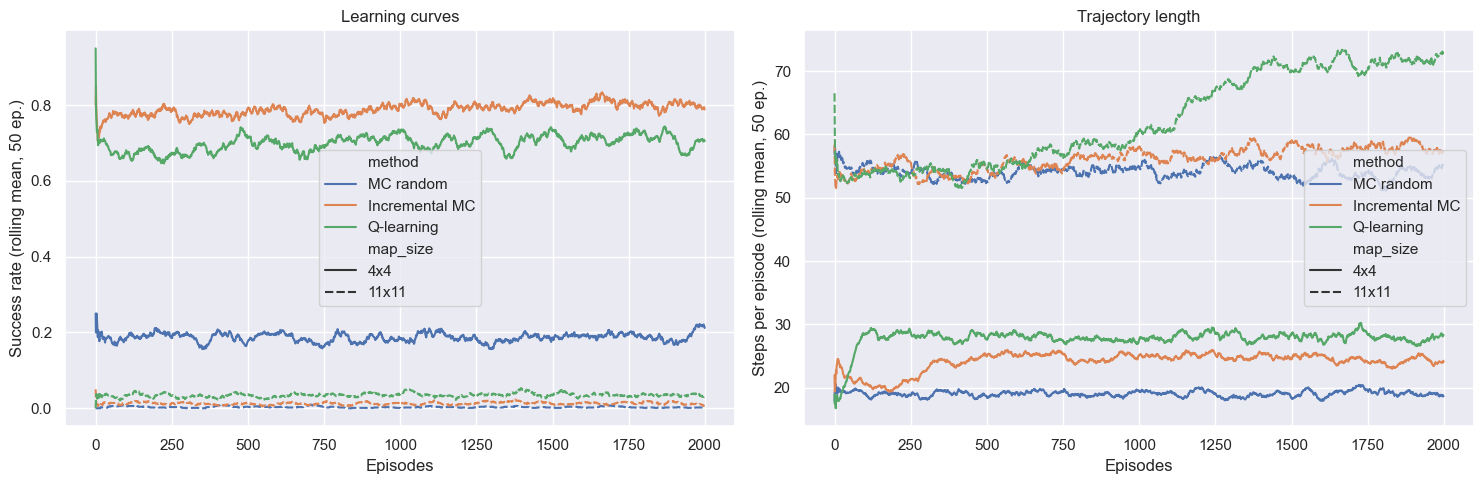

In [80]:
def plot_comparison(res_all, st_all, window=50):
    """Learning curves (success rate) and trajectory lengths per method and map size."""
    # Success rate = reward per episode averaged over runs, smoothed with a rolling mean
    success = (
        res_all.groupby(["map_size", "method", "Episodes"])["Rewards"].mean()
        .groupby(level=["map_size", "method"])
        .transform(lambda s: s.rolling(window, min_periods=1).mean())
        .reset_index()
    )
    steps = st_all.copy()
    steps["Steps"] = steps.groupby(["map_size", "method"])["Steps"].transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    )

    # Fixed orders so colours / line styles mean the same thing in both panels
    order = dict(hue="method", hue_order=list(METHODS),
                 style="map_size", style_order=[f"{m}x{m}" for m in MAP_SIZES])

    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
    sns.lineplot(data=success, x="Episodes", y="Rewards", **order, ax=ax[0])
    ax[0].set(ylabel=f"Success rate (rolling mean, {window} ep.)", title="Learning curves")
    sns.lineplot(data=steps, x="Episodes", y="Steps", **order, ax=ax[1])
    ax[1].set(ylabel=f"Steps per episode (rolling mean, {window} ep.)", title="Trajectory length")
    fig.tight_layout()
    fig.savefig(params.savefig_folder / "frozenlake_method_comparison.png", bbox_inches="tight")
    plt.show()


plot_comparison(res_all, st_all)

## Report

**MC implementation:** First-Visit / Every-Visit, because ...

**Hyperparameters**

| Method | γ | ε | α | episodes | runs | how chosen |
|---|---|---|---|---|---|---|
| MC random | | – | – | | | |
| Incremental MC | | | 1/N or … | | | |
| Q-learning | | | | | | |

**Per method**

- *MC random*: Is the value function estimated correctly? Is the right policy learned? 4x4 vs 11x11?
- *Incremental MC*: ...
- *Q-learning*: ...

**General discussion (max. 1 page)**

...